# 10 · Stress tests and error analysis

**Goal:** use the pipeline's *actual* predictions to see when and why the models fail - and what that means for using such a system on real data.

Unlike the earlier notebooks this one reads the shipped results (`results/predictions_main.parquet`, `results/predictions_intervals.parquet`, …) instead of refitting models, because the lessons here are about the final experiment itself.
Every number below is a number from the pipeline.

In [1]:
from tutorial_utils import *
style()
main = pd.read_parquet(RESULTS / "predictions_main.parquet")
main["variant"] = np.where(main.feature_set.isin(["-", None]), main.model, main.model + " [" + main.feature_set + "]")
main["crop"] = main.crop_id.map(CROPS)
prim = main[(main.scenario == "realistic") & (main.handling == "handled") & main.scored]
test, val = prim[prim.partition == "test"], prim[prim.partition == "validation"]
print(f"{len(main):,} prediction rows over {main.variant.nunique()} model variants; primary setting = realistic data, cleaning on")
print("columns:", list(main.columns))

295,262 prediction rows over 28 model variants; primary setting = realistic data, cleaning on
columns: ['series', 'market_id', 'crop_id', 'horizon', 'origin_week', 'target_week', 'origin_date', 'target_date', 'ref_price', 'y_obs', 'y_latent', 'y_audit_suspect', 'y_event_affected', 'y_regime', 'y_event_ids', 'horizon_vol8', 'price_stale_weeks', 'y_pred', 'scored', 'model', 'feature_set', 'fallback_to_naive', 'log_change_pred', 'n_train', 'fit_s', 'pred_s', 'seed', 'params', 'scenario', 'handling', 'partition', 'variant', 'crop']


## 1. The headline - and the gap between validation and test
Skill versus naive on the validation window and on the untouched test window (mean over horizons 1, 2, 4):

In [2]:
def mae_by(df, by):
    return df.assign(e=(df.y_obs - df.y_pred).abs()).groupby(by).e.mean()
core = ["naive", "seasonal_naive", "ma4", "ridge [E4]", "sarima", "decision_tree [E4]", "random_forest [E4]", "hist_gb [E4]", "ridge_cropint [E4]"]
tab = pd.DataFrame({part: mae_by(d[d.variant.isin(core)], ["variant", "horizon"]).unstack().mean(axis=1) for part, d in [("validation MAE", val), ("test MAE", test)]}).loc[core]
tab["validation skill %"] = (1 - tab["validation MAE"] / tab.loc["naive", "validation MAE"]) * 100
tab["test skill %"] = (1 - tab["test MAE"] / tab.loc["naive", "test MAE"]) * 100
tab["MAE rise val→test %"] = (tab["test MAE"] / tab["validation MAE"] - 1) * 100
tab.round(2)

,validation MAE,test MAE,validation skill %,test skill %,MAE rise val→test %
variant,,,,,
naive,4.99,6.16,0.00,0.00,23.62
seasonal_naive,8.38,11.25,-68.05,-82.52,34.26
ma4,5.57,7.39,-11.66,-19.85,32.68
ridge [E4],4.11,5.79,17.66,6.03,41.08
sarima,4.61,6.43,7.65,-4.37,39.70
decision_tree [E4],4.81,6.10,3.55,1.00,26.89
random_forest [E4],4.01,5.78,19.65,6.19,44.33
hist_gb [E4],4.02,5.76,19.43,6.61,43.28
ridge_cropint [E4],3.92,5.39,21.46,12.56,37.61


Every model's error is much higher on the test window, and the learned models lose more than naive does: skill of about 18-20% on validation shrinks to about 6% on test for Ridge, the random forest and gradient boosting.
(`ridge_cropint` - a Ridge with crop-specific slopes - was a diagnostic outside the core eight; it holds up best.) **Validation overstated what the test window would show**, because the test window contains disruptions that training never did.

## 2. Before and after the regime shift
At week 140 transport costs jump by 35% and stay there (EV13). Skill before and after, for the same models:

In [3]:
t = test.copy(); t["period"] = np.where(t.target_week < 140, "target week < 140", "target week ≥ 140")
sk = {}
for per, d in t.groupby("period"):
    m = mae_by(d[d.variant.isin(core)], "variant"); sk[per] = (1 - m / m["naive"]) * 100
pd.DataFrame(sk).loc[core].round(1)

,target week < 140,target week ≥ 140
variant,,
naive,0.0,0.0
seasonal_naive,-10.0,-103.5
ma4,-20.5,-20.2
ridge [E4],19.0,3.1
sarima,11.5,-8.0
decision_tree [E4],1.4,0.9
random_forest [E4],20.9,2.5
hist_gb [E4],23.2,2.4
ridge_cropint [E4],18.2,11.2


Before week 140 the better models are ~20% better than naive; after it, only 2-3% (the crop-interaction Ridge keeps about 11%). **The advantage largely disappeared once the world changed.** (We compare only two windows, so we cannot say whether it faded or fell off a cliff - exercise 1 asks you to probe that.)
The main cause (transport costs) did not vary in training, so there was nothing to learn.

## 3. By crop
Skill versus naive per crop on the test window (mean over horizons):

In [4]:
by_crop = mae_by(test[test.variant.isin(core)], ["crop", "variant"]).unstack()
((1 - by_crop.div(by_crop["naive"], axis=0)) * 100)[core[1:]].round(1)

variant,seasonal_naive,ma4,ridge [E4],sarima,decision_tree [E4],random_forest [E4],hist_gb [E4],ridge_cropint [E4]
crop,,,,,,,,
Irish potatoes,-115.6,-42.3,10.3,-11.6,-3.8,-8.1,-5.8,22.4
Maize,26.9,-33.7,2.9,5.8,18.3,33.5,27.9,22.0
Onions,-97.2,-22.6,-4.3,1.3,6.9,16.7,11.7,11.3
Tomatoes,-91.4,-11.4,8.4,-5.1,-2.0,2.9,5.1,8.6


* **Maize** is where the *seasonal* naive (+27%) and the tree ensembles (+28% to +34%) gain the most - the seasonal naive is the strongest baseline there (notebook 07).
* **Irish potatoes**: the tree ensembles are **worse than naive** (-4% to -8%), while the Ridge-type models gain (+10% and +22%). Why? Look at the next section.
* **Onions**: plain Ridge is slightly *worse* than naive (-4%) while the tree ensembles gain 12-17%: no model family wins everywhere.
* **Tomatoes**: small skill - they are so volatile that most of the movement is unforecastable noise.

## 4. The potato puzzle: trees and a rising market
Tree ensembles predict averages of what they saw in training. If prices climb to levels never seen before, they cannot follow. Let us check whether the potato price left its historical range, using the clean-world audit file:

In [5]:
world = pd.read_csv(DATA / "clean_world_audit.csv")
prior_max = world[world.week_index <= VAL_END].groupby("crop_id").latent_price_kes_kg.max()
later = world[world.week_index > VAL_END].merge(prior_max.rename("prior_max"), left_on="crop_id", right_index=True)
rng_tab = pd.DataFrame({"max price weeks 1-130": prior_max.round(1), "max price test": later.groupby("crop_id").latent_price_kes_kg.max().round(1),
                        "share of test rows above prior max %": (later.latent_price_kes_kg > later.prior_max).groupby(later.crop_id).mean().mul(100).round(0)})
rng_tab.index = rng_tab.index.map(CROPS); rng_tab

,max price weeks 1-130,max price test,share of test rows above prior max %
crop_id,,,
Maize,70.4,68.2,0.0
Tomatoes,153.6,168.2,2.0
Irish potatoes,70.2,79.2,15.0
Onions,114.6,113.0,0.0


Only potatoes (and, barely, tomatoes) went beyond their earlier range. So "trees cannot extrapolate" explains the potato case but **not** the whole story: tomatoes and onions also rose without leaving their range.
Let us look at the direction of the errors after week 140 for the random forest. Signed error = observed − forecast; positive means under-predicted.

In [6]:
rf = test[(test.variant == "random_forest [E4]") & (test.target_week >= 140)].assign(err=lambda d: d.y_obs - d.y_pred)
rfi = test[(test.variant == "ridge_cropint [E4]") & (test.target_week >= 140)].assign(err=lambda d: d.y_obs - d.y_pred)
bias = pd.DataFrame({"RF: share under-predicted %": rf.groupby("crop").err.apply(lambda e: (e > 0).mean() * 100),
                     "RF: mean signed error": rf.groupby("crop").err.mean(), "Ridge+crop-int: mean signed error": rfi.groupby("crop").err.mean()})
bias.round(2)

,RF: share under-predicted %,RF: mean signed error,Ridge+crop-int: mean signed error
crop,,,
Irish potatoes,90.91,5.46,3.19
Maize,38.82,-0.67,-0.19
Onions,66.67,1.59,2.16
Tomatoes,73.17,11.37,9.46


After the shift the forecasts **lag a rising market**: most forecasts for potatoes (91%), tomatoes (73%) and onions (67%) are too low. The crop-interaction linear model is biased in the same direction - less so for potatoes and slightly for tomatoes, slightly *more* for onions.
Two mechanisms are mixed together: range extrapolation (potatoes) and a driver that never varied in training (all three crops). Distinguishing them is part of a good error analysis - and this one is not fully settled by the data we have.

## 5. The same bet wins and loses
The model tends to bet that an unusually high price will fall back (mean reversion). Look at tomatoes during the spike (random forest, horizon 4): forecasts issued at the **peak** versus on the **plateau**.

In [7]:
tom = test[(test.variant == "random_forest [E4]") & (test.horizon == 4) & (test.crop == "Tomatoes")].copy()
nv = test[(test.variant == "naive") & (test.horizon == 4) & (test.crop == "Tomatoes")][["series", "origin_week", "y_pred"]].rename(columns={"y_pred": "naive"})
tom = tom.merge(nv, on=["series", "origin_week"]); tom["gain_vs_naive"] = (tom.y_obs - tom.naive).abs() - (tom.y_obs - tom.y_pred).abs()
cols = ["series", "origin_week", "target_week", "y_obs", "naive", "y_pred", "gain_vs_naive"]
print("BEST (model much better than naive):"); print(tom.sort_values("gain_vs_naive", ascending=False).head(5)[cols].round(1).to_string(index=False))
print("\nWORST (model much worse than naive):"); print(tom.sort_values("gain_vs_naive").head(5)[cols].round(1).to_string(index=False))

BEST (model much better than naive):
       series  origin_week  target_week  y_obs  naive  y_pred  gain_vs_naive
MKT-02|CRP-02          152          156  105.9  158.1   124.4           33.7
MKT-02|CRP-02          151          155  117.0  145.4   116.1           27.5
MKT-04|CRP-02          151          155  113.3  144.3   117.5           26.8
MKT-01|CRP-02          152          156  121.8  161.5   137.1           24.4
MKT-04|CRP-02          152          156   97.1  137.8   114.1           23.7

WORST (model much worse than naive):
       series  origin_week  target_week  y_obs  naive  y_pred  gain_vs_naive
MKT-04|CRP-02          148          152  137.8  140.0   109.7          -25.9
MKT-04|CRP-02          147          151  144.3  146.6   118.6          -23.5
MKT-03|CRP-02          150          154  116.0  118.9    92.4          -20.8
MKT-02|CRP-02          150          154  133.0  118.8   101.2          -17.5
MKT-01|CRP-02          147          151  129.1  131.1   109.9          -17.3


The best cases are issued at origin weeks 151-152, when the spike peaked and then fell; the worst at origin weeks 147-150, while prices stayed high. The model cannot tell a *temporary* spike from a *new level*. That is a
limitation of the information it has - it never saw anything like the transport shift - not a bug.

Plot one example (Nakuru tomatoes, horizon 4):

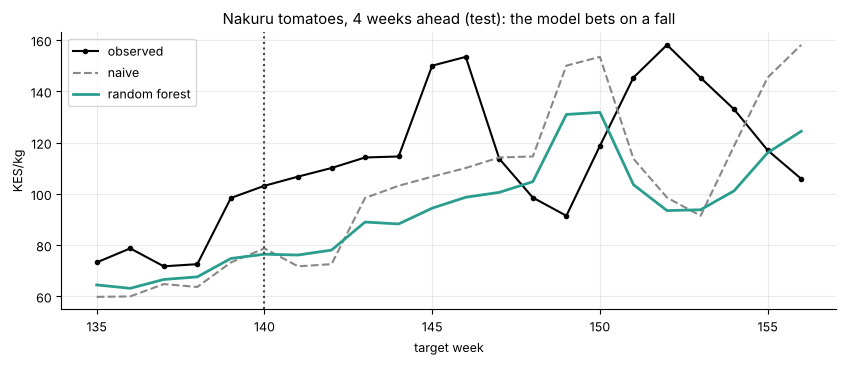

In [8]:
ser = "MKT-02|CRP-02"
a = test[(test.series == ser) & (test.horizon == 4) & (test.variant == "random_forest [E4]")].set_index("target_week")
b = test[(test.series == ser) & (test.horizon == 4) & (test.variant == "naive")].set_index("target_week")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(a.index, a.y_obs, "k.-", label="observed"); ax.plot(b.index, b.y_pred, "--", color="#888", label="naive"); ax.plot(a.index, a.y_pred, color="#2a9d8f", lw=2, label="random forest")
ax.axvline(140, color="#444", ls=":"); ax.set_title("Nakuru tomatoes, 4 weeks ahead (test): the model bets on a fall"); ax.set_xlabel("target week"); ax.set_ylabel("KES/kg"); ax.legend();

## 6. Data-quality scenarios and the value of cleaning
Test MAE for each scenario and handling mode (mean over horizons) - the table behind notebook 03:

In [9]:
sc = pd.read_csv(RESULTS / "scenario_comparison_test.csv")
sc.pivot(index="variant", columns="combo", values="mean_over_horizons").loc[["Naive", "Moving average (4w)", "Ridge [E4]", "Random Forest [E4]", "HistGradientBoosting [E4]"]].round(2)

combo,clean|handled,realistic|handled,realistic|raw,stressed|handled,stressed|raw
variant,,,,,
Naive,5.81,6.16,10.32,6.74,9.65
Moving average (4w),7.26,7.39,11.51,7.82,10.72
Ridge [E4],5.47,5.79,8.07,6.36,9.40
Random Forest [E4],5.54,5.78,10.82,6.21,8.12
HistGradientBoosting [E4],5.48,5.76,10.55,6.29,9.71


With cleaning (`handled`) the error rises gradually from clean to realistic to stressed data. Without it (`raw`) the error is far higher, and note that "stressed raw" is not worse than "realistic raw": the damage of uncleaned errors depends on *where the random errors happened to fall* - one realisation of the world.
Do not read an ordering into the raw columns.

## 7. Prediction intervals: are they honest?
An 80% interval should contain the outcome 80% of the time. The pipeline built two kinds around gradient boosting (quantile regression; split-conformal using validation errors).

In [10]:
iv = pd.read_parquet(RESULTS / "predictions_intervals.parquet")
iv = iv[(iv.partition == "test") & iv.scored].copy()
for k in ("qr", "cf"):
    iv[f"cover_{k}"] = (iv.y_obs >= iv[f"lower_{k}"]) & (iv.y_obs <= iv[f"upper_{k}"])
cov = iv.groupby("horizon")[["cover_qr", "cover_cf"]].mean().mul(100).rename(columns={"cover_qr": "quantile regression %", "cover_cf": "split conformal %"})
cov_crop = iv.assign(crop=iv.crop_id.map(CROPS)).groupby(["crop", "horizon"]).cover_cf.mean().unstack().mul(100)
print("empirical coverage of the nominal 80% intervals, test window"); print(cov.round(0).to_string()); print("\nconformal intervals by crop:"); print(cov_crop.round(0).to_string())

empirical coverage of the nominal 80% intervals, test window
         quantile regression %  split conformal %
horizon                                          
1                         73.0               75.0
2                         64.0               69.0
4                         61.0               69.0

conformal intervals by crop:
horizon            1     2     4
crop                            
Irish potatoes  86.0  68.0  63.0
Maize           65.0  72.0  70.0
Onions          79.0  74.0  78.0
Tomatoes        72.0  60.0  64.0


Overall coverage is 61-75% (conformal 69-75%) against a target of 80%: the bands are on average **too narrow**, because they assume future errors will resemble past ones - and the test window broke that assumption. By crop the picture is mixed: from 60% (tomatoes, horizon 2) up to 86% (potatoes, horizon 1), i.e. the bands are miscalibrated in *both* directions and worst for the volatile crop.
A real service should present such bands as *optimistic*, widen them in turbulent periods, and always show the naive forecast alongside the model.

## 8. What would change on real data?
Everything above is a statement about a laboratory. Before taking this pipeline to real prices, work through the list below (from the specification, section 16.1), and note which parts of the project help:

| Question for the real data | What this project gives you |
|---|---|
| What exactly is the price (farm-gate, wholesale, retail), unit, grade, variety? | The schema (`docs/data_dictionary.md`) to fill in; the generator becomes an *ingestion* step |
| When is each value *published* and *revised*? | The as-known machinery and the late-delivery test (notebook 05); you must add revision timestamps - revisions are **not** simulated here |
| Is missingness random? (It usually is not: reporting changes, closed markets, seasonal gaps) | The annotation table and missingness plots (notebook 03); replace the random masks by the observed pattern |
| What are the *real* shocks, and how will you label them without hindsight? | Separate event labels vs quality labels (notebook 02); real events are rarely documented in advance |
| Is a one-year seasonal pattern even identifiable? | Notebook 04: with two training cycles, be sceptical |
| Is the test period representative? Do you have *several* different periods? | Rolling origins (notebook 06); consider several test blocks |
| How wrong can you afford to be? | Skill vs naive and honest intervals (notebooks 07, 10); always report the baseline |

**Three lessons from the whole project**
1. *Information beats algorithms*: the choice between forest, boosting and a good linear model mattered less than which features they were given - and cross-market information was the most valuable external signal.
2. *Honest evaluation is most of the work*: leakage, purging, rolling origins, uncertainty on the comparison, and keeping the test window for last.
3. *Know where it breaks*: a model that is 20% better than naive in calm weeks and 2% better after a regime change is an accurate description of a *useful but fragile* tool.

## Exercises
1. In section 2, split the test window at week 145 instead of 140, and then compute skill week by week. Did the advantage fade gradually or fall off a cliff?
2. Repeat section 5 for **potatoes** (Kisumu, horizon 4). Does the "bet on a fall" story hold, or is the pattern different (under-prediction throughout)?
3. Compute skill by *market* for the test window. Is any market consistently easier? (Compare with `results/breakdown_by_market_test.csv`.)
4. The `stressed` scenario has two market outages (Kisumu weeks 120-127, Mombasa 141-147). Compare the Kisumu and Mombasa errors for the `stressed|handled` models inside and outside those weeks.
5. *Open question:* design an experiment that would separate "range extrapolation" from "unseen driver" as the cause of the under-prediction. (Hint: the generator lets you re-run with the transport shift switched off.)

**Where this lives in the pipeline:** `scripts/05_analyse.py` (all breakdowns), `scripts/07_build_reports.py` (`reports/ERROR_ANALYSIS.md`, `reports/FINAL_REPORT.md`).